# TP4 — Voir les images comme des images : le réseau convolutif (CNN)
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- Comprendre ce qu'est une **convolution** (un filtre qui glisse sur l'image) et un **pooling**
- Construire un **CNN** (Conv2D, MaxPooling2D, Flatten) et **compter ses paramètres**
- **Comparer honnêtement** un CNN à un réseau dense, sur des images propres puis décalées
- Découvrir qu'**un modèle peut s'effondrer** sur une variation qu'il n'a jamais vue

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`reshape`  ·  `convolve2d`  ·  `layers.Conv2D`  ·  `layers.MaxPooling2D`  ·  `layers.Flatten`  ·  `padding`  ·  `np.roll`  ·  `np.argmax`  ·  `get_weights`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Les données : les mêmes chiffres qu'au TP3
Mêmes images 8 × 8, même découpage. On retrouve des tableaux **aplatis** (64 nombres par image), comme au TP3.

In [2]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(1347, 64) (450, 64)


## 🎯 Étape 2 — Remettre les images en forme d'images
Un CNN a besoin de **la structure de l'image** : il veut savoir qu'un pixel est **à côté** d'un autre. On remet donc chaque vecteur de 64 nombres en un tableau `(8, 8, 1)` : **hauteur, largeur, nombre de canaux** (1 canal = niveaux de gris ; une image en couleurs en aurait 3).

**À faire :** Créez `I_train` et `I_test` à partir de `X_train` et `X_test`, de forme `(n, 8, 8, 1)`.

> 💡 **Indice** : `reshape(-1, 8, 8, 1)` : le `-1` laisse NumPy calculer le nombre d'images.

In [4]:
# DONE : créer I_train et I_test
I_train = X_train.reshape(-1, 8, 8, 1)
I_test = X_test.reshape(-1, 8, 8, 1)

In [5]:
# ✅ Contrôle (ne pas modifier)
controle(I_train.shape == (1347, 8, 8, 1) and I_test.shape == (450, 8, 8, 1), 'Images en bonne forme', 'Attendu (1347, 8, 8, 1) et (450, 8, 8, 1)')

✅ Images en bonne forme


## Étape 3 — Une convolution, à la main
Une **convolution** fait **glisser un petit filtre** (ici 3 × 3 nombres) sur l'image. En chaque position, on multiplie le filtre par les pixels dessous et on additionne : on obtient une **nouvelle image** qui met en évidence un motif. Ce filtre-ci repère les **contours verticaux**. **Dans un CNN, les valeurs des filtres ne sont pas choisies : elles sont apprises.**

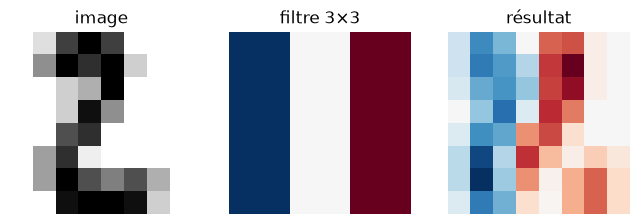

In [6]:
from scipy.signal import convolve2d
image = I_train[0, :, :, 0]
filtre = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])
sortie = convolve2d(image, filtre, mode="same")
fig, ax = plt.subplots(1, 3, figsize=(8, 2.6))
ax[0].imshow(image, cmap="gray_r"); ax[0].set_title("image")
ax[1].imshow(filtre, cmap="RdBu"); ax[1].set_title("filtre 3×3")
ax[2].imshow(sortie, cmap="RdBu"); ax[2].set_title("résultat")
for a in ax: a.axis("off")
plt.show()

In [7]:
sortie.shape

(8, 8)

## Étape 4 — La référence : le réseau dense du TP3
On entraîne ici, en une cellule, le réseau dense du TP3 pour servir de point de comparaison.

In [8]:
keras.utils.set_random_seed(42)
ann = keras.Sequential([layers.Input(shape=(64,)), layers.Dense(64, activation="relu"), layers.Dense(32, activation="relu"), layers.Dense(10, activation="softmax")])
ann.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
ann.fit(X_train, y_train, epochs=40, batch_size=32, validation_split=0.2, verbose=0)
acc_ann = float(np.mean(np.argmax(ann.predict(X_test, verbose=0), axis=1) == y_test))
print(f"Réseau dense : {acc_ann:.3f} de bonnes réponses | {ann.count_params()} paramètres")

Réseau dense : 0.960 de bonnes réponses | 6570 paramètres


## 🎯 Étape 5 — Construire le CNN
Les briques d'un CNN :
- **`Conv2D(16, 3)`** : 16 filtres de 3 × 3, appris. `padding="same"` garde la taille de l'image.
- **`MaxPooling2D(2)`** : on découpe en carrés de 2 × 2 et on **ne garde que le maximum** : l'image est réduite de moitié (8 × 8 devient 4 × 4), on garde l'essentiel.
- **`Flatten`** : on met à plat pour finir avec des couches denses.

**À faire :** Construisez `cnn` : entrée `(8, 8, 1)` → **Conv2D 16 filtres 3×3, ReLU, padding same** → **MaxPooling2D 2×2** → **Conv2D 32 filtres 3×3, ReLU** (sans padding) → **Flatten** → **Dense 10, softmax**. Compilez comme au TP3 (adam, sparse_categorical_crossentropy, accuracy).

> 💡 **Indice** : Après la 2ᵉ convolution sans padding, 4 × 4 devient 2 × 2. Combien de valeurs après `Flatten` ? `cnn.summary()` vous le dit.

In [15]:
keras.utils.set_random_seed(42)
# TODO : construire et compiler cnn
cnn = keras.Sequential([
    layers.Input(shape=(8, 8, 1)),
    layers.Conv2D(16, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(10, activation='softmax')
])
cnn.summary()
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 2, 2, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,090 (23.79 KB)

 Trainable params: 6,090 (23.79 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# ✅ Contrôle (ne pas modifier)
controle(cnn.count_params() == 6090, 'CNN correct : 6 090 paramètres', 'Attendu 6 090 paramètres, obtenu ' + str(cnn.count_params()))

✅ CNN correct : 6 090 paramètres


### ✍️ Question
**Retrouvez à la main le nombre de paramètres de la **première couche de convolution** (16 filtres de 3 × 3, 1 canal d'entrée). Vérifiez avec `summary()`.**

*Votre réponse (2 à 4 lignes) :*

> Comme il n'y a qu'une matrice à traiter en entrée, chaque filtre a 3x3 = 9 poids et un biais, soient 10 paramètres par filtre, soient 16x10 = 160 paramètres pour la couche.

## 🎯 Étape 6 — Entraîner le CNN
Même procédure que pour un réseau dense. Seule la forme des données d'entrée change.

**À faire :** Entraînez `cnn` sur `I_train` : **40 epochs**, batch de 32, **20 % de validation**, sans affichage. Stockez dans `histoire_cnn`.

In [16]:
# DONE
histoire_cnn = cnn.fit(I_train, y_train, epochs=40, batch_size=32, validation_split=0.2, verbose=0)

In [17]:
# ✅ Contrôle (ne pas modifier)
controle(len(histoire_cnn.history['loss']) == 40, '40 epochs effectués', 'Attendu 40 epochs')

✅ 40 epochs effectués


## 🎯 Étape 7 — Comparer le CNN et le réseau dense
Mêmes images, même découpage : on compare sur le test, sans tricher.

**À faire :** Calculez `acc_cnn` (précision du CNN sur `I_test`) puis rangez dans un tableau pandas `comparaison` : le nom du modèle, son **nombre de paramètres** et sa **précision** (pour le réseau dense `ann` et pour `cnn`).

> 💡 **Indice** : `np.argmax(cnn.predict(I_test), axis=1) == y_test`, puis `np.mean`. `model.count_params()`.

In [20]:
# TODO : acc_cnn et le tableau comparaison
acc_cnn = np.mean(np.argmax(cnn.predict(I_test), axis=1) == y_test)
comparaison = pd.DataFrame([["Dense",ann.count_params(),acc_ann],["CNN",cnn.count_params(),acc_cnn]],columns=["modèle", "nbr paramètres", "précision"])
comparaison.head()

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


,modèle,nbr paramètres,précision
0,Dense,6570,0.960000
1,CNN,6090,0.975556


In [21]:
# ✅ Contrôle (ne pas modifier)
controle(acc_cnn > 0.94 and len(comparaison) == 2, 'Comparaison faite (CNN : %.3f)' % acc_cnn, 'Attendu acc_cnn > 0.94 et un tableau de 2 lignes')

✅ Comparaison faite (CNN : 0.976)


### ✍️ Question
**Le CNN bat-il nettement le réseau dense sur ces images ? Pourquoi, à votre avis, l'écart est-il petit ici ?**

*Votre réponse (2 à 4 lignes) :*

>Les deux modèles donnent des précisions proches. Comme vu précédemment, certaines images sont difficiles à reconnaitre car elles manquent de précision, la dimension 8x8 est trop juste pour espérer un résultat sensiblement meilleur.

## 🎯 Étape 8 — Le test qui fait mal : décaler les images d'un pixel
Un CNN est censé reconnaître un motif **où qu'il soit** dans l'image. Vérifions : on **décale toutes les images de test d'un pixel vers la droite**. Un humain lit toujours le même chiffre.

**À faire :** Créez `I_test_decale` (les images de test décalées d'**un pixel sur l'axe des colonnes**). Calculez `acc_ann_decale` et `acc_cnn_decale`. Attention : le réseau dense attend des images **aplaties**.

> 💡 **Indice** : `np.roll(tableau, 1, axis=2)`. Pour le réseau dense : `I_test_decale.reshape(-1, 64)`.

In [ ]:
# DONE : I_test_decale, acc_ann_decale, acc_cnn_decale
I_test_decale = np.roll(I_test, 1, axis=2)
acc_ann_decale = float(np.mean(np.argmax(ann.predict(I_test_decale.reshape(-1,64), verbose=0), axis=1) == y_test))
acc_cnn_decale = np.mean(np.argmax(cnn.predict(I_test_decale), axis=1) == y_test)
print("acc_ann_decale = ",acc_ann_decale,", acc_cnn_decale = ",acc_cnn_decale)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
acc_ann_decale =  0.40444444444444444 , acc_cnn_decale =  0.5177777777777778


In [23]:
# ✅ Contrôle (ne pas modifier)
controle(acc_ann_decale < acc_ann and acc_cnn_decale < acc_cnn, 'Les deux modèles perdent en précision', 'Attendu : précision plus basse sur images décalées')

✅ Les deux modèles perdent en précision


### ✍️ Question
**Les deux modèles s'effondrent-ils ? Le CNN fait-il mieux ? Pourquoi un si petit décalage les trompe-t-il, et que pourrait-on faire ?**

*Votre réponse (2 à 4 lignes) :*

> Les deux modèles s'effondrent, même si CNN s'en sort un peu moins mal. L'apprentissage se base sur des images avec des bords, pas uniquement sur la zone où le chiffre est écrit. Il faudrait caler systématiquement cette zone en haut à gauche (par ex.), en rajoutant des blancs à droite et en bas. Idéalement, il faudrait même zoomer chaque chiffre pour que chacun fasse la même taille.

## Étape 9 — Que cherchent les filtres ?
On affiche les **16 filtres 3 × 3 appris** par la première couche : ce sont les « motifs » que le réseau a trouvé utiles. À cette taille, difficiles à interpréter, mais c'est bien **eux** que le réseau combine.

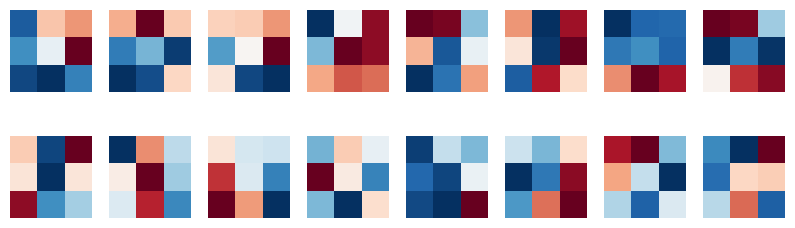

In [24]:
conv1 = [l for l in cnn.layers if isinstance(l, layers.Conv2D)][0]
filtres = conv1.get_weights()[0]
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(filtres[:, :, 0, k], cmap="RdBu"); ax.axis("off")
plt.show()

## ✅ Ce qu'il faut retenir
- Une **convolution** = un petit filtre appris qui glisse sur l'image. **Pooling** = on réduit en gardant le maximum.
- Un CNN a **moins de paramètres** qu'un réseau dense équivalent, car un filtre est réutilisé partout.
- **Un CNN n'est pas automatiquement meilleur** : sur de petites images propres, il fait comme un réseau dense.
- **Un modèle qui marche sur ses données de test peut s'effondrer sur une variation simple** : tester la robustesse est indispensable.